# Synthetic training-data examples -- a qualitative figure

8 example images per class, one row per class (4 classes x 8 columns = 32
images), sampled uniformly at random from the phase-classifier ablation
study's "5x" synthetic training set
([`experiments/`](../experiments/README.md)) -- pooled across both the
train/val splits.

Needs `experiments/data_cache/` populated locally first -- run, in order,
from `experiments/data/`:

```bash
python extract_real_patches.py
python build_splits.py
python generate_synthetic.py
python gan_render_synthetic.py
```

(see [experiments/README.md](../experiments/README.md) for the full
pipeline). Also needs the `notebooks` extra
(`.venv/bin/pip install -e ".[notebooks]"`). Writes
`results/synthetic_examples_figure/synthetic_examples_figure.{pdf,png}`
(vector + 300dpi raster).

In [1]:
import csv
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

DATA_CACHE = Path("../experiments/data_cache")
OUT_DIR = Path("../results/synthetic_examples_figure")

# Same order experiments/README.md lists the classifier's own classes in.
CLASSES = ("prometaphase", "metaphase", "ring_shape", "anaphase_telophase")
N_PER_CLASS = 8
SEED = 0

## Pool the two splits' manifests and sample 8 rows per class

Both manifests share the same `path,class` schema (`path` relative to
`DATA_CACHE`, written by `gan_render_synthetic.py`); pooling them samples
from the same 5x population the classifier actually trained on (train+val
together), not just whichever split happens to be larger. Sampling is
stratified by class (8 independent draws per class) rather than one draw
from the pooled set, so every class is represented regardless of its
share of the pool.

In [2]:
rows = []
for split in ("train", "val"):
    with open(DATA_CACHE / "splits" / f"synth_{split}.csv", newline="") as f:
        rows.extend(csv.DictReader(f))
print(f"{len(rows)} synthetic images available across train+val")

rng = np.random.default_rng(SEED)
by_class = {cls: [r for r in rows if r["class"] == cls] for cls in CLASSES}
sample = {cls: rng.choice(by_class[cls], size=N_PER_CLASS, replace=False) for cls in CLASSES}
for cls in CLASSES:
    print(f"{cls:20s} {len(by_class[cls])} available, sampled {len(sample[cls])}")

9292 synthetic images available across train+val
prometaphase         2323 available, sampled 8
metaphase            2323 available, sampled 8
ring_shape           2323 available, sampled 8
anaphase_telophase   2323 available, sampled 8


## Render the grid

One row per class (row-labelled on the left), 8 columns -- no per-image
labels or borders within a row, since the row label already identifies
the class.

wrote ../results/synthetic_examples_figure/synthetic_examples_figure.pdf and .png


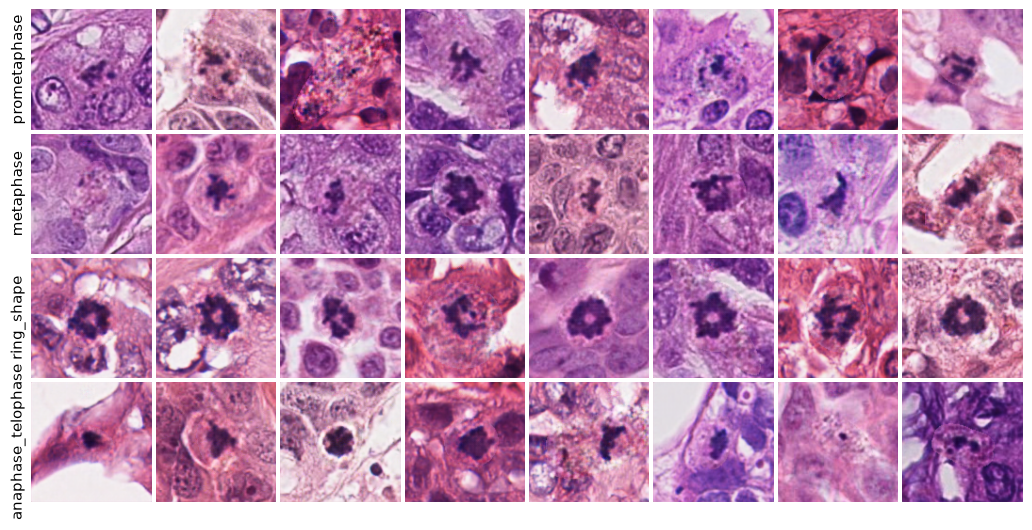

In [3]:
fig, axes = plt.subplots(len(CLASSES), N_PER_CLASS, figsize=(N_PER_CLASS * 1.6, len(CLASSES) * 1.6))
for row_axes, cls in zip(axes, CLASSES):
    for ax, row in zip(row_axes, sample[cls]):
        img = Image.open(DATA_CACHE / row["path"]).convert("RGB")
        ax.imshow(img)
        ax.set_xticks([])
        ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_visible(False)
    row_axes[0].set_ylabel(cls, fontsize=11, rotation=90)
fig.subplots_adjust(wspace=0.03, hspace=0.03)

OUT_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(OUT_DIR / "synthetic_examples_figure.pdf", bbox_inches="tight")
fig.savefig(OUT_DIR / "synthetic_examples_figure.png", dpi=300, bbox_inches="tight")
print(f"wrote {OUT_DIR / 'synthetic_examples_figure.pdf'} and .png")
plt.show()